# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent, HumanRuleAgent, EpsilonGreedyAgent, UCBAgent

## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [2]:
TEAM_LOG_FILES = [
    "fishing_log_antonsen.json",
    "fishing_log_raad.json",
    "fishing_log_toukouro.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
# spots, catches = choices(logs[0], season=1)

## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [3]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

All results: regret is in kg; efficiency is in percent.
 season                agent    n  regret_mean  regret_sd  regret_median  regret_p10  regret_p90  efficiency_mean  efficiency_sd  catch_mean
      1 Epsilon-greedy (0.1) 1000        55.14      48.35          42.40        6.39      128.42            78.86          18.00      204.70
      1           Human rule 1000        78.86      32.14          75.35       39.90      123.09            69.82          11.20      182.53
      1               Random 1000        79.32      29.86          77.50       42.18      119.41            69.67          10.19      180.89
      1            UCB (c=2) 1000        25.06      11.17          22.55       13.99       39.61            90.25           4.46      235.27
      2 Epsilon-greedy (0.1) 1000        24.16      19.83          20.30        1.00       53.24            72.41          21.98       63.19
      2           Human rule 1000        26.38      13.81          25.85        9.20       45.20  

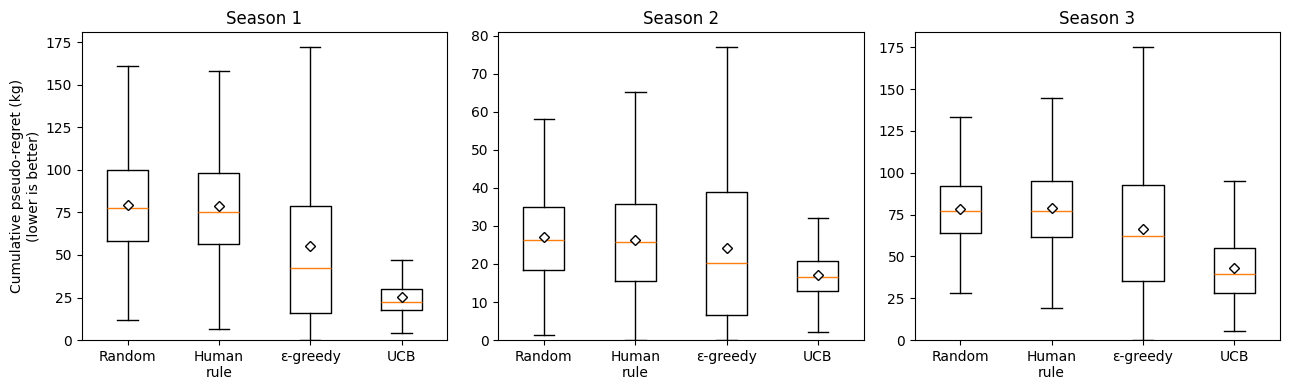

In [12]:
# Task 5, Part 1: evaluate all four agents on the SAME 1,000 bays per season.
# Each agent gets its own reproducible random generator; the simulator is not
# revealed to the agents. Hidden means are used ONLY after play() for evaluation.
import pandas as pd

N_BAYS = 1000
AGENT_FACTORIES = {
    "Random": lambda seed: RandomAgent(seed=seed),
    "Human rule": lambda seed: HumanRuleAgent(n_spots=5, seed=seed),
    "Epsilon-greedy (0.1)": lambda seed: EpsilonGreedyAgent(seed=seed, epsilon=0.1),
    "UCB (c=2)": lambda seed: UCBAgent(seed=seed, c=2.0),
}

def evaluate_finished_bay(bay):
    """Compute pseudo-regret and efficiency after the agent has finished."""
    info = bay.reveal()  # Never used by the agent itself!
    expected = 0.0
    for day, (spot, catch) in enumerate(bay.history, start=1):
        means = info["means"]
        if "means_after_change" in info and day >= info["change_day"]:
            means = info["means_after_change"]
        expected += means[spot]
    optimal = bay.best_possible()
    return {
        "actual": bay.total,
        "expected": expected,
        "optimal": optimal,
        "regret": optimal - expected,
        "efficiency": 100 * expected / optimal,
        "luck": bay.total - expected,
    }

records = []
for season in (1, 2, 3):
    for bay_seed in range(N_BAYS):
        for name, make_agent in AGENT_FACTORIES.items():
            bay = FishingBay(season=season, seed=bay_seed)
            agent = make_agent(seed=1_000_000 + bay_seed)
            play(agent, bay)
            records.append({
                "season": season,
                "bay_seed": bay_seed,
                "agent": name,
                **evaluate_finished_bay(bay),
            })

results = pd.DataFrame(records)
summary = (results.groupby(["season", "agent"])
           .agg(n=("regret", "size"),
                regret_mean=("regret", "mean"),
                regret_sd=("regret", "std"),
                regret_median=("regret", "median"),
                regret_p10=("regret", lambda x: x.quantile(.10)),
                regret_p90=("regret", lambda x: x.quantile(.90)),
                efficiency_mean=("efficiency", "mean"),
                efficiency_sd=("efficiency", "std"),
                catch_mean=("actual", "mean"))
           .reset_index())
print("All results: regret is in kg; efficiency is in percent.")
print(summary.round(2).to_string(index=False))


# Fig. 1: distribution of final regret, one panel per season
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
labels = list(AGENT_FACTORIES)
short = ["Random", "Human\nrule", "ε-greedy", "UCB"]

for ax, season in zip(axes, (1, 2, 3)):
    data = [results.loc[(results.season == season) &
                        (results.agent == name), "regret"].to_numpy()
            for name in labels]
    ax.boxplot(data, tick_labels=short, showfliers=False,
               showmeans=True, meanprops={"marker": "D", "markerfacecolor": "white",
                                          "markeredgecolor": "black", "markersize": 5})
    ax.set_title(f"Season {season}")
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Cumulative pseudo-regret (kg)\n(lower is better)")
fig.tight_layout()
fig.savefig("fig1_regret_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [5]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)


# Task 5, Part 2: Compare agents with human players
PLAYER_NAMES = ["Kaisa", "Synne", "Fayad"]

comparison = []

for player, log in zip(PLAYER_NAMES, logs):
    for season in (1, 2, 3):

        # Reconstruct the original bay
        bay = FishingBay.from_log(log, season)

        # Replay the human player's choices
        spots, catches = choices(log, season)

        for spot in spots:
            bay.fish(spot)

        # Verify that the original catches match
        assert np.allclose(
            [catch for spot, catch in bay.history],
            catches
        )

        # Evaluate the human player
        comparison.append({
            "player": player,
            "season": season,
            "agent": "Human",
            **evaluate_finished_bay(bay),
        })

        # Evaluate all four agents on the same bay
        for name, make_agent in AGENT_FACTORIES.items():
            bay = FishingBay.from_log(log, season)
            agent = make_agent(seed=1_000_000 + season)

            play(agent, bay)

            comparison.append({
                "player": player,
                "season": season,
                "agent": name,
                **evaluate_finished_bay(bay),
            })

# Create results table
human_bay_results = pd.DataFrame(comparison)

regret_table = human_bay_results.pivot(
    index=["player", "season"],
    columns="agent",
    values="regret"
)

print("Cumulative pseudo-regret (kg): lower is better")
display(regret_table.round(1))

# Save results for the report
human_bay_results.to_csv(
    "task5_human_bays.csv", index=False
)


Cumulative pseudo-regret (kg): lower is better


agent          Epsilon-greedy (0.1)  Human  Human rule  Random  UCB (c=2)
player season                                                            
Fayad  1                        6.4   50.6        50.7    45.1       22.5
       2                       58.0   25.9        51.4    36.9       31.7
       3                       26.3   40.4        53.0    52.7       25.6
Kaisa  1                       50.4   69.8        52.8    74.0       22.6
       2                       40.3   29.3        50.4    44.2       22.3
       3                       95.6   64.5        59.7    46.2       36.2
Synne  1                       90.0  110.0       102.5   107.3       18.5
       2                       78.0   23.3        50.7    50.0       16.7
       3                       48.0   74.4       104.5    97.4       49.6

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

Season 2: best agent = UCB (c=2) (regret 17.1 kg, efficiency 80.3%)
    Epsilon-greedy (0.1)   loses   7.0 kg more (s.e. 0.6,  11.9 s.e.)
    Human rule             loses   9.3 kg more (s.e. 0.4,  24.5 s.e.)
    Random                 loses  10.1 kg more (s.e. 0.3,  37.2 s.e.)

Season 3: best agent = UCB (c=2) (regret 43.2 kg, efficiency 83.3%)
    Epsilon-greedy (0.1)   loses  22.9 kg more (s.e. 1.2,  18.5 s.e.)
    Human rule             loses  35.9 kg more (s.e. 0.8,  42.2 s.e.)
    Random                 loses  35.3 kg more (s.e. 0.8,  46.3 s.e.)



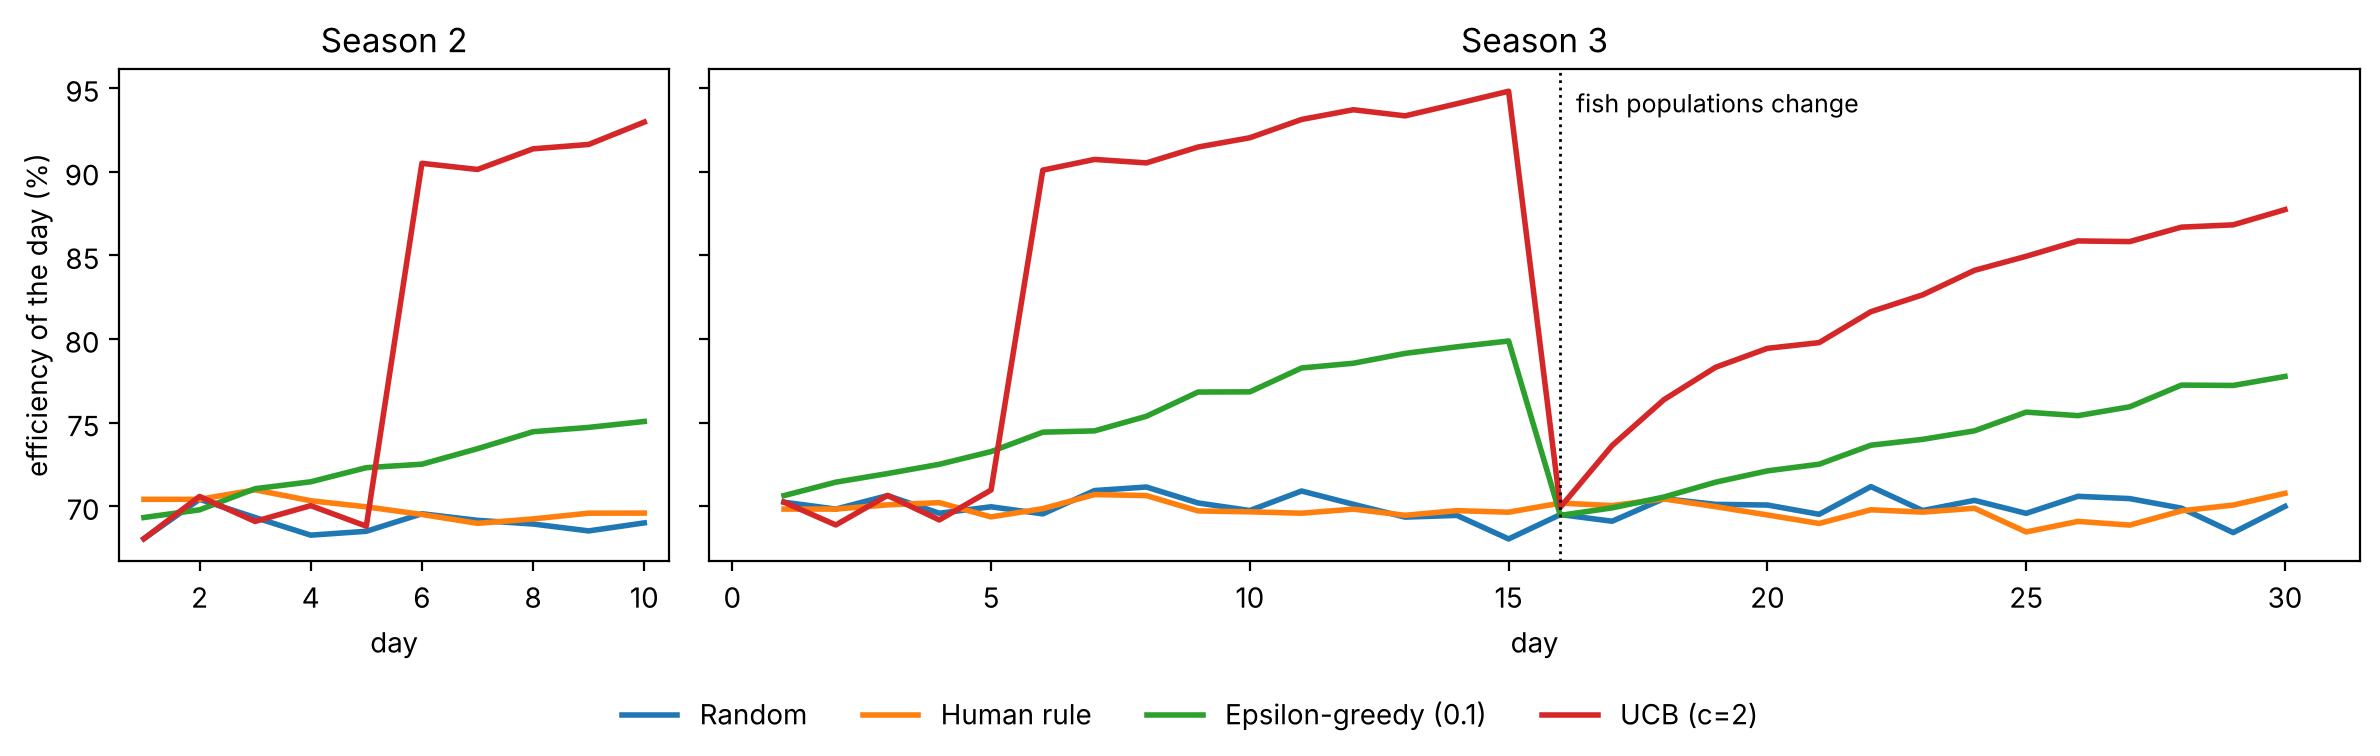

In [6]:
# Task 5, Part 3: best agent for Seasons 2 and 3.
# All agents played the same bays (Part 1), so we compare them bay by bay:
# for every other agent, the mean difference of regret with the best agent and its standard error.
for season in (2, 3):
    table = results[results.season == season].pivot(index="bay_seed", columns="agent", values="regret")
    best = table.mean().idxmin()
    print(f"Season {season}: best agent = {best} "
          f"(regret {table[best].mean():.1f} kg, efficiency "
          f"{results[(results.season == season) & (results.agent == best)].efficiency.mean():.1f}%)")
    for name in table.columns.drop(best):
        diff = table[name] - table[best]
        se = diff.std(ddof=1) / np.sqrt(len(diff))
        print(f"    {name:22s} loses {diff.mean():5.1f} kg more (s.e. {se:.1f}, {diff.mean() / se:5.1f} s.e.)")
    print()


def daily_efficiency(bay):
    """For each day: true mean of the chosen spot / best true mean that day (in %)."""
    info = bay.reveal()
    out = []
    for day, (spot, catch) in enumerate(bay.history, start=1):
        means = info["means"]
        if "means_after_change" in info and day >= info["change_day"]:
            means = info["means_after_change"]
        out.append(100 * means[spot] / max(means))
    return out


# Day-by-day quality of the choices, on the same bays and agent seeds as in Part 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, gridspec_kw={"width_ratios": [1, 3]})
for ax, season in zip(axes, (2, 3)):
    for name, make_agent in AGENT_FACTORIES.items():
        days = []
        for bay_seed in range(N_BAYS):
            bay = FishingBay(season=season, seed=bay_seed)
            play(make_agent(seed=1_000_000 + bay_seed), bay)
            days.append(daily_efficiency(bay))
        ax.plot(range(1, bay.days + 1), np.mean(days, axis=0), lw=2, label=name)
    ax.set_title(f"Season {season}"); ax.set_xlabel("day")
axes[0].set_ylabel("efficiency of the day (%)")
axes[1].axvline(16, color="black", lw=1, ls=":")
axes[1].text(16.3, 95, "fish populations change", fontsize=9, va="top")
fig.legend(*axes[1].get_legend_handles_labels(), frameon=False, ncol=4, loc="lower center")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Season 2.** UCB is the best agent (17.1 kg of regret, 80.3% efficiency). Epsilon-greedy loses 7.0 kg more, the human rule 9.3 kg
more and random play 10.1 kg more; all these differences are real (more than 10 standard errors). The figure shows why: UCB spends
days 1 to 5 trying every spot, then fishes the spot with the best average and reaches about 90% from day 6. Epsilon-greedy improves
slowly because it rarely leaves its first spot, and the human rule stays at the level of random play.

**Season 3.** UCB is the best agent again (43.2 kg of regret, 83.3%), 22.9 kg ahead of Epsilon-greedy and about 35 kg ahead of the
human rule and random play. On day 16 UCB and Epsilon-greedy fall to the level of random play: what they learned is no longer true.
UCB recovers faster because its bonus grows for the spots that were not visited for a long time, so it goes back to them and finds
the new best spot. The human rule is not affected by the change because it does not keep an estimate of each spot: it changes spot
according to its last catches only, and stays at the level of random play before and after day 16.

## 4. One parameter

Study the effect of one parameter of one method.

We study **epsilon**, the probability of a random day in `EpsilonGreedyAgent`, from 0 (pure greedy) to 0.5,
on the same 1000 bays per season as in Part 1.

Mean regret (kg) of Epsilon-greedy
epsilon  0.00  0.01  0.05  0.10  0.15  0.20  0.30  0.50
season                                                 
1        78.0  75.6  62.5  55.1  51.6  49.2  48.5  53.5
2        26.2  25.9  25.0  24.2  23.5  23.0  22.3  22.6
3        78.7  77.1  71.7  66.1  63.5  60.4  60.8  62.0

Mean efficiency (%) of Epsilon-greedy
epsilon  0.00  0.01  0.05  0.10  0.15  0.20  0.30  0.50
season                                                 
1        70.2  71.0  76.0  78.9  80.2  81.1  81.4  79.5
2        70.1  70.4  71.5  72.4  73.1  73.7  74.6  74.1
3        69.9  70.5  72.5  74.6  75.6  76.8  76.6  76.2


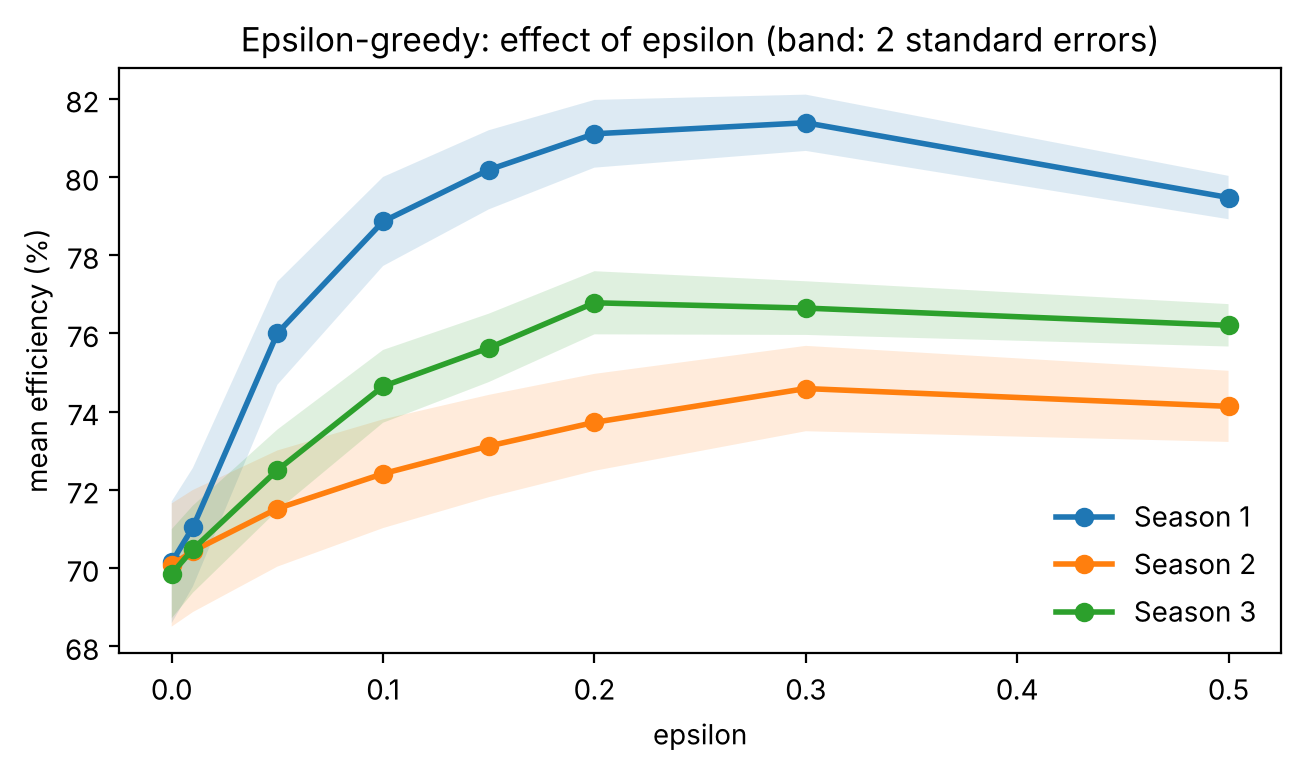

In [7]:
# Task 5, Part 4: effect of epsilon in Epsilon-greedy, for each season
EPSILONS = [0, 0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]

sweep = []
for season in (1, 2, 3):
    for epsilon in EPSILONS:
        for bay_seed in range(N_BAYS):
            bay = FishingBay(season=season, seed=bay_seed)
            play(EpsilonGreedyAgent(seed=1_000_000 + bay_seed, epsilon=epsilon), bay)
            sweep.append({"season": season, "epsilon": epsilon, **evaluate_finished_bay(bay)})
sweep = pd.DataFrame(sweep)

sweep_summary = sweep.groupby(["season", "epsilon"]).agg(
    regret_mean=("regret", "mean"), efficiency_mean=("efficiency", "mean"),
    efficiency_se=("efficiency", lambda x: x.std() / np.sqrt(len(x)))).reset_index()
print("Mean regret (kg) of Epsilon-greedy")
print(sweep_summary.pivot(index="season", columns="epsilon", values="regret_mean").round(1).to_string())
print("\nMean efficiency (%) of Epsilon-greedy")
print(sweep_summary.pivot(index="season", columns="epsilon", values="efficiency_mean").round(1).to_string())

# Efficiency is used for the figure because it is comparable between seasons of different lengths.
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for season in (1, 2, 3):
    s = sweep_summary[sweep_summary.season == season]
    ax.fill_between(s.epsilon, s.efficiency_mean - 2 * s.efficiency_se, s.efficiency_mean + 2 * s.efficiency_se, alpha=0.15)
    ax.plot(s.epsilon, s.efficiency_mean, "o-", lw=2, label=f"Season {season}")
ax.set_xlabel("epsilon"); ax.set_ylabel("mean efficiency (%)")
ax.set_title("Epsilon-greedy: effect of epsilon (band: 2 standard errors)")
ax.legend(frameon=False)
plt.show()

**Observations.**

- **The regret falls (and the efficiency rises) when epsilon increases up to 0.2 - 0.3**, in every season: 81.4% in Season 1,
  74.6% in Season 2 and 76.8% in Season 3. At 0.5 too many days are spent at random and the efficiency falls again.
- The best epsilon is high because the estimates start at 0: without random days the agent never leaves the first spot it tried
  (epsilon = 0 gives the level of random play). The random days are its only way to discover the other spots.
- Even with its best epsilon, Epsilon-greedy stays below UCB (81.4% against 90.3% in Season 1): exploring at random is less
  efficient than exploring the spots that are still uncertain.

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [8]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

# Task 6
from agents import LinearRegressionAgent, NoContextAgent

N_CTX = 200                                    # contextual bays (seeds 0 to 199), 300 days each


def evaluate_contextual_bay(bay):
    """Regret (kg) and efficiency (%) after the season: the best spot depends on the day."""
    true_means = bay.reveal()                  # Never used by the agent itself!
    spots = [spot for x, spot, catch in bay.history]
    expected = true_means[np.arange(bay.days), spots].sum()
    optimal = bay.best_possible()
    return {"actual": bay.total, "expected": expected, "optimal": optimal,
            "regret": optimal - expected, "efficiency": 100 * expected / optimal}


def run_contextual(make_agent):
    rows = []
    for bay_seed in range(N_CTX):
        bay = ContextualBay(seed=bay_seed)
        play(make_agent(seed=1_000_000 + bay_seed), bay)
        rows.append({"bay_seed": bay_seed, **evaluate_contextual_bay(bay)})
    return pd.DataFrame(rows)

Random contextual agent: 1945.7 kg over 300 days


**What the simulator does** (code of `ContextualBay`): the mean catch of a spot is
`base + weights . (conditions / maximum)`, with a different base and different weights for every spot, so the
best spot changes from day to day. We therefore fit **one linear regression per spot** (`LinearRegressionAgent`
in `agents.py`) on the days that spot was fished. After `n_init` visits to each spot, the agent acts **only on its
predictions**: every day it fishes the spot with the highest predicted catch. We first look at how `n_init` changes
the result on 200 bays.

In [9]:
N_INIT = [1, 2, 3, 5, 10, 20]
grid = []
for n_init in N_INIT:
    r = run_contextual(lambda seed, n=n_init: LinearRegressionAgent(n_init=n, seed=seed))
    grid.append({"n_init": n_init, "warm-up days": 5 * n_init, "regret_mean": r.regret.mean(),
                 "efficiency_mean": r.efficiency.mean(), "worst_bay_efficiency": r.efficiency.min(),
                 "bays_below_80%": (r.efficiency < 80).mean()})
print("Predictions only, after n_init visits per spot (200 bays)")
print(pd.DataFrame(grid).round(3).to_string(index=False))

Predictions only, after n_init visits per spot (200 bays)
 n_init  warm-up days  regret_mean  efficiency_mean  worst_bay_efficiency  bays_below_80%
      1             5      231.367           92.012                36.436           0.085
      2            10      142.696           94.869                50.177           0.035
      3            15      149.395           94.770                62.011           0.025
      5            25      166.434           94.353                85.436           0.000
     10            50      257.176           91.407                83.352           0.000
     20           100      456.733           84.935                76.750           0.040


**Observations.**

- **With one visit per spot, acting only on the predictions is fragile**: 92.0% on average, but 8.5% of the bays are below 80%
  and the worst one is at 36.4%.
- **More visits before trusting the regressions remove these failures**: from 5 visits per spot, no bay is below 80% (worst bay
  85.4%). Each regression then starts with 5 catches instead of 1, so one bad day can no longer make a good spot look bad.
- **Too many visits cost days**: the warm-up takes `5 * n_init` days, so with 20 visits (100 days of 300) the mean falls to 84.9%.
  `n_init = 5` is the best compromise: our final agent.

**Comparison with the best agent of Part III.** UCB (`c = 2`) is the best agent of Part III; it plays the
contextual bays without looking at the conditions (`NoContextAgent`). We compare it with the regression agent after
one visit per spot, and with our final agent (5 visits per spot).

                       agent  regret_mean  regret_sd  efficiency_mean  efficiency_sd  worst_bay  bays_below_80
                      Random      1305.01     403.60            57.12           9.63      29.80           1.00
  UCB, no context (Part III)       190.75     171.63            93.13           6.43      70.00           0.06
         Regression, 1 visit       231.37     275.05            92.01           9.39      36.44           0.08
Regression, 5 visits (final)       166.43      62.85            94.35           2.32      85.44           0.00


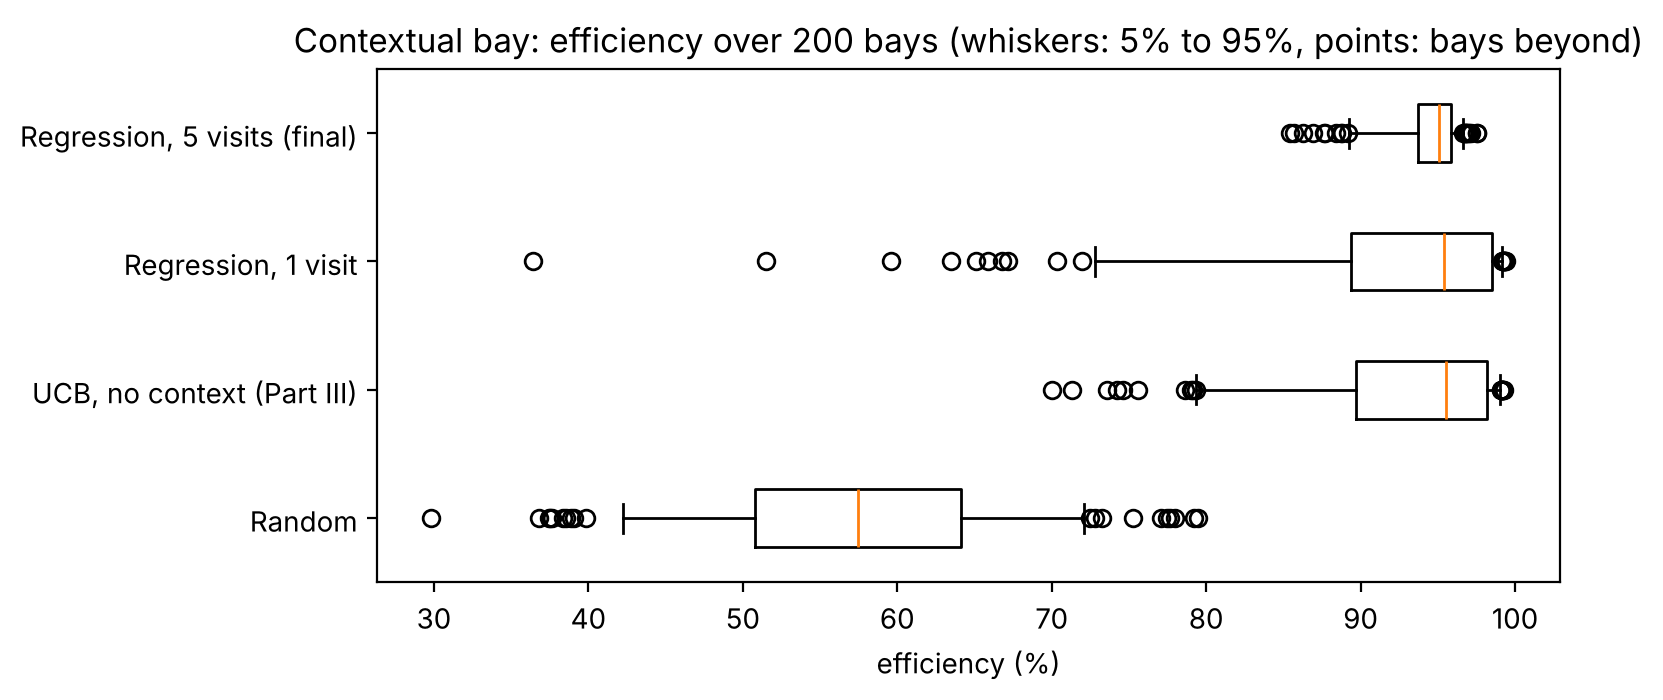

In [10]:
CTX_FACTORIES = {
    "Random": lambda seed: RandomContextualAgent(seed=seed),
    "UCB, no context (Part III)": lambda seed: NoContextAgent(UCBAgent(seed=seed, c=2.0)),
    "Regression, 1 visit": lambda seed: LinearRegressionAgent(n_init=1, seed=seed),
    "Regression, 5 visits (final)": lambda seed: LinearRegressionAgent(n_init=5, seed=seed),
}
ctx_results = pd.concat([run_contextual(make).assign(agent=name) for name, make in CTX_FACTORIES.items()])
ctx_summary = (ctx_results.groupby("agent", sort=False)
               .agg(regret_mean=("regret", "mean"), regret_sd=("regret", "std"),
                    efficiency_mean=("efficiency", "mean"), efficiency_sd=("efficiency", "std"),
                    worst_bay=("efficiency", "min"), bays_below_80=("efficiency", lambda x: (x < 80).mean()))
               .reset_index())
print(ctx_summary.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
labels = list(CTX_FACTORIES)
ax.boxplot([ctx_results.loc[ctx_results.agent == n, "efficiency"] for n in labels],
           tick_labels=labels, orientation="horizontal", whis=(5, 95))
ax.set_xlabel("efficiency (%)")
ax.set_title("Contextual bay: efficiency over 200 bays (whiskers: 5% to 95%, points: bays beyond)")
fig.tight_layout()
plt.show()
ctx_results.to_csv("task6_contextual_bays.csv", index=False)

**Observations.**

- **Using the conditions helps a little on average**: 94.4% for the final agent (166 kg of regret), against 93.1% for UCB
  (191 kg), the best agent of Part III, which ignores the conditions. UCB is already good because in many bays one spot is the
  best on most days.
- **The main gain is regularity**: the worst bay of the final agent is at 85.4%, against 70.0% for UCB and 36.4% for the
  regression agent with one visit per spot.
- **Limit of our fix**: after the warm-up the agent never checks a spot again. If five unlucky catches made a good spot look bad,
  the error would never be corrected; with 5 catches per spot this did not happen on our 200 bays.

**A case where acting only on the predictions fails.** We take the bay where the regression agent with one visit
per spot does worst, and count the days it spent at each spot, compared with the number of days each spot is truly
the best.

In [11]:
worst = int(ctx_results[ctx_results.agent == "Regression, 1 visit"].sort_values("efficiency").bay_seed.iloc[0])
bay = ContextualBay(seed=worst)
print(f"Bay {worst}. Days on which each spot is truly the best: {np.bincount(bay.reveal().argmax(axis=1), minlength=5)}")
for name in ["Regression, 1 visit", "Regression, 5 visits (final)"]:
    agent = CTX_FACTORIES[name](seed=1_000_000 + worst)
    play(agent, bay)
    days = np.bincount([spot for x, spot, catch in bay.history], minlength=5)
    print(f"  {name:29s} days at each spot: {days}   efficiency {evaluate_contextual_bay(bay)['efficiency']:.1f}%")

# What the agent with one visit per spot believed at the end of the season
agent = CTX_FACTORIES["Regression, 1 visit"](seed=1_000_000 + worst)
play(agent, bay)
x_mean = np.array([20.0, 1.5, 1.0])            # average conditions
print("\nAverage conditions: predicted catch per spot", np.round(agent.predict(x_mean), 1),
      "| true mean catch per spot", np.round(bay.reveal().mean(axis=0), 1))

Bay 156. Days on which each spot is truly the best: [296   2   0   0   2]
  Regression, 1 visit           days at each spot: [  1   4   3   1 291]   efficiency 36.4%
  Regression, 5 visits (final)  days at each spot: [280   5   5   5   5]   efficiency 94.9%



Average conditions: predicted catch per spot [0.9 0.9 1.1 0.5 3.5] | true mean catch per spot [9.2 1.8 2.9 3.  3.4]


**What goes wrong.** In bay 156, spot 0 is the best spot on 296 days out of 300 (true mean 9.2 kg). With one visit per spot,
the agent fished it once, on a bad day, so its regression predicts about 1 kg there, below spot 4. It never goes back to spot 0,
so its prediction is never corrected: it spends 291 days at spot 4 and reaches only 36.4%. The error confirms itself, because the
agent only collects data where it already believes the catch is good. This is the difference with supervised learning, where the
data are given: here the agent chooses its own data.

**Fix.** With 5 visits per spot, the regression of spot 0 is fitted on 5 catches, which show that the spot is good: on the same
bay the agent spends 280 days at spot 0 and reaches 94.9%.